# 01. Data Understanding & EDA

**Module:** IT3091 Machine Learning  
**Group:** 2026-DS-37 (Y3.S1.WE.DS.0102)  
**Owner:** Hariluxshun R (IT24102466)  
**Completed:** 2026-10-10

## Business Problem

A telecommunications company wants to identify customers who may stop using its services and understand the factors associated with customer churn.

## Dataset

**Name:** Telco Customer Churn  
**Source:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn  
**File:** `WA_Fn-UseC_-Telco-Customer-Churn.csv`  
**Records:** 7,043 customers  
**Row meaning:** One row represents one customer.

**Verified dataset SHA-256:**

`88BE4B93FBE0CC83421AF1C503794C97C342ECA914C1576DB7C276E61D61358A`

## How to Run

1. Place the original CSV in the project's `data/Original/` directory.
2. Open this notebook from the `notebooks/` directory.
3. Select **Kernel → Restart & Run All**.
4. Review the generated tables, charts and observations.

Figures are saved to the `reports/` directory where specified by the code.

## Analysis Approach

This notebook explores:

- Customer churn distribution
- Contract types and churn
- Customer tenure
- Monthly charges
- Internet services
- Other customer characteristics associated with churn

The visualizations and observations help identify patterns that may be useful during preprocessing and model development.

Each analysis section explains what the results show and why they are relevant to customer churn.

## 1. Setup

In [1]:
import sys
print(sys.executable)

c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Scripts\python.exe


In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

FIG_DIR = "../reports"
os.makedirs(FIG_DIR, exist_ok=True)   # charts are saved here for the final report

## 2. Load the data

In [3]:
df = pd.read_csv("../data/Original/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. First look: size, types and the target

In [4]:
print("Shape (rows, columns):", df.shape)
print()
print(df.dtypes)

Shape (rows, columns): (7043, 21)

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


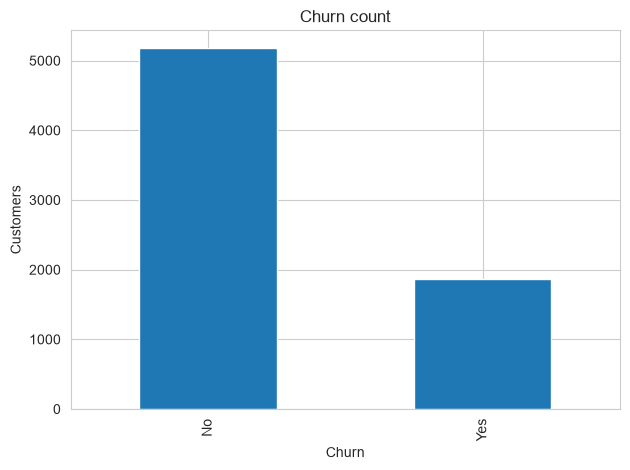

In [5]:
print(df["Churn"].value_counts())
print()
print(df["Churn"].value_counts(normalize=True).round(3))

df["Churn"].value_counts().plot(kind="bar", title="Churn count")
plt.ylabel("Customers")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/churn_count.png", dpi=150, bbox_inches="tight")
plt.show()

**Chart:** Churn count (target variable)
**Shows:** 7,043 customers and 21 columns. 5,174 customers stayed (73.5%) and 1,869 churned (26.5%).
**So what:** the classes are imbalanced. A model that always predicts "No churn" would be about 73.5% accurate and catch no churners at all, so models must be judged on recall, F1 and ROC-AUC, not accuracy alone. Imbalance handling must be applied to the training set only.

## 4. Data quality checks

In [6]:
print("True nulls in the whole table:", df.isnull().sum().sum())

# Hidden blanks: text cells that contain only spaces (isnull() cannot see these)
blank_counts = {c: int((df[c].astype(str).str.strip() == "").sum())
                for c in df.select_dtypes("object").columns}
print("Hidden blanks by column:", {k: v for k, v in blank_counts.items() if v})

True nulls in the whole table: 0
Hidden blanks by column: {'TotalCharges': 11}


C:\Users\ASUS\AppData\Local\Temp\ipykernel_16392\2104901226.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for c in df.select_dtypes("object").columns}


**Check:** True missing values and hidden blank strings  
**Shows:** The original dataset has 0 true null values (`isnull()`), but 11 whitespace-only entries in `TotalCharges`. No other hidden blank columns were identified in the earlier data-quality check.  
**So what:** A standard null check alone would miss these 11 entries. We inspect their tenure and billing values before deciding how to handle them. Member 2 will document the final preprocessing choice.

In [7]:
# Convert to numbers WITHOUT changing the raw df
tc_num = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Blank / unreadable TotalCharges values:", tc_num.isnull().sum())

df[tc_num.isnull()][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Blank / unreadable TotalCharges values: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Chart:** The 11 rows with a blank `TotalCharges`
**Shows:** 11 customers have a blank `TotalCharges`. All have tenure = 0 and Churn = No, and all have a `MonthlyCharges` value.
**So what:** these are new customers who have not been billed yet, so treating blank `TotalCharges` as zero is a reasonable EDA assumption, although the raw file does not explicitly encode a zero. The blanks are spaces, not real nulls, so a standard null check misses them, and the column is read as text. Setting them to 0 keeps all 7,043 rows. Dropping them would also be defensible (only 0.16% of the data, none are churners). M2 makes the final call and logs it.

In [8]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
print("Unique IDs:", df["customerID"].nunique())
print("SeniorCitizen values:", df["SeniorCitizen"].unique())

Duplicate rows: 0
Duplicate customer IDs: 0
Unique IDs: 7043
SeniorCitizen values: [0 1]


In [9]:
cat_cols = df.select_dtypes(include="object").columns
for col in cat_cols:
    if col not in ["customerID", "TotalCharges"]:
        print(col, "->", df[col].unique())

gender -> <ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str
Partner -> <ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str
Dependents -> <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
PhoneService -> <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
MultipleLines -> <ArrowStringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
InternetService -> <ArrowStringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
OnlineSecurity -> <ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
OnlineBackup -> <ArrowStringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
DeviceProtection -> <ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
TechSupport -> <ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingTV -> <ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingMovies -> <ArrowStringArray>
['No', 'Yes', 'No internet serv

C:\Users\ASUS\AppData\Local\Temp\ipykernel_16392\466793869.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns


**Chart:** Duplicates, ID column and values inside each categorical column
**Shows:** no duplicate rows and no duplicate customer IDs (7,043 unique IDs). `SeniorCitizen` is already 0/1. `MultipleLines` has a third value "No phone service", and six columns (`OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`) have a third value "No internet service". `InternetService` has 3 levels, `Contract` 3 levels and `PaymentMethod` 4 levels.
**So what:** `customerID` is a pure identifier and should be dropped before modeling. The "No phone service" and "No internet service" values repeat information already in `PhoneService` and `InternetService`, so they can be merged into "No" (see the follow-up check in section 9). `SeniorCitizen` uses 0/1 while the other yes/no columns use text, so encoding must make them consistent.

### Data issues list (handed to M2)

| # | Issue | Where | How it affects the task | Suggested handling |
|---|---|---|---|---|
| 1 | Stored as text, 11 blanks (spaces, all tenure 0, all Churn = No) | `TotalCharges` | Cannot be used as a number; blanks hide from `isnull()` | Convert to numeric; set the 11 blanks to 0 (or drop them) |
| 2 | Unique identifier, no predictive value | `customerID` | A model could memorise IDs instead of learning patterns | Drop before modeling |
| 3 | Class imbalance, 73.5% No / 26.5% Yes | `Churn` | Accuracy is misleading | Class weights or resampling on the training set only; judge by recall, F1, ROC-AUC |
| 4 | Numeric 0/1 while other yes/no columns use text | `SeniorCitizen` | Inconsistent encoding | Make consistent when encoding |
| 5 | Redundant third value ("No phone service" / "No internet service") | `MultipleLines` and six service columns | Extra categories that add no information | Consider merging into "No"; evaluate whether preserving the distinct category is useful |
| 6 | Multi-level categories | `InternetService`, `Contract`, `PaymentMethod` | Need numeric form for models | One-hot encode |
| 7 | No duplicate rows or IDs | whole table | none | none |

## 5. Analysis copy for EDA

In [10]:
# The raw df stays untouched. df_eda is an EDA-only copy.
df_eda = df.copy()

# EDA-only choice: blanks set to 0 (M2 makes the final preprocessing decision and logs it)
df_eda["TotalCharges"] = pd.to_numeric(df_eda["TotalCharges"], errors="coerce").fillna(0)

# 1 = churned, 0 = stayed, so the mean of this column is the churn rate
df_eda["ChurnFlag"] = (df_eda["Churn"] == "Yes").astype(int)

print(df_eda["TotalCharges"].dtype, df_eda["ChurnFlag"].mean().round(3))

float64 0.265


## 6. Churn rate by category

In [11]:
cols = ["Contract", "InternetService", "PaymentMethod", "SeniorCitizen",
        "Partner", "Dependents", "PaperlessBilling", "TechSupport"]

for col in cols:
    print(df_eda.groupby(col)["ChurnFlag"].mean().round(3).sort_values(ascending=False))
    print()

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: ChurnFlag, dtype: float64

InternetService
Fiber optic    0.419
DSL            0.190
No             0.074
Name: ChurnFlag, dtype: float64

PaymentMethod
Electronic check             0.453
Mailed check                 0.191
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152
Name: ChurnFlag, dtype: float64

SeniorCitizen
1    0.417
0    0.236
Name: ChurnFlag, dtype: float64

Partner
No     0.330
Yes    0.197
Name: ChurnFlag, dtype: float64

Dependents
No     0.313
Yes    0.155
Name: ChurnFlag, dtype: float64

PaperlessBilling
Yes    0.336
No     0.163
Name: ChurnFlag, dtype: float64

TechSupport
No                     0.416
Yes                    0.152
No internet service    0.074
Name: ChurnFlag, dtype: float64



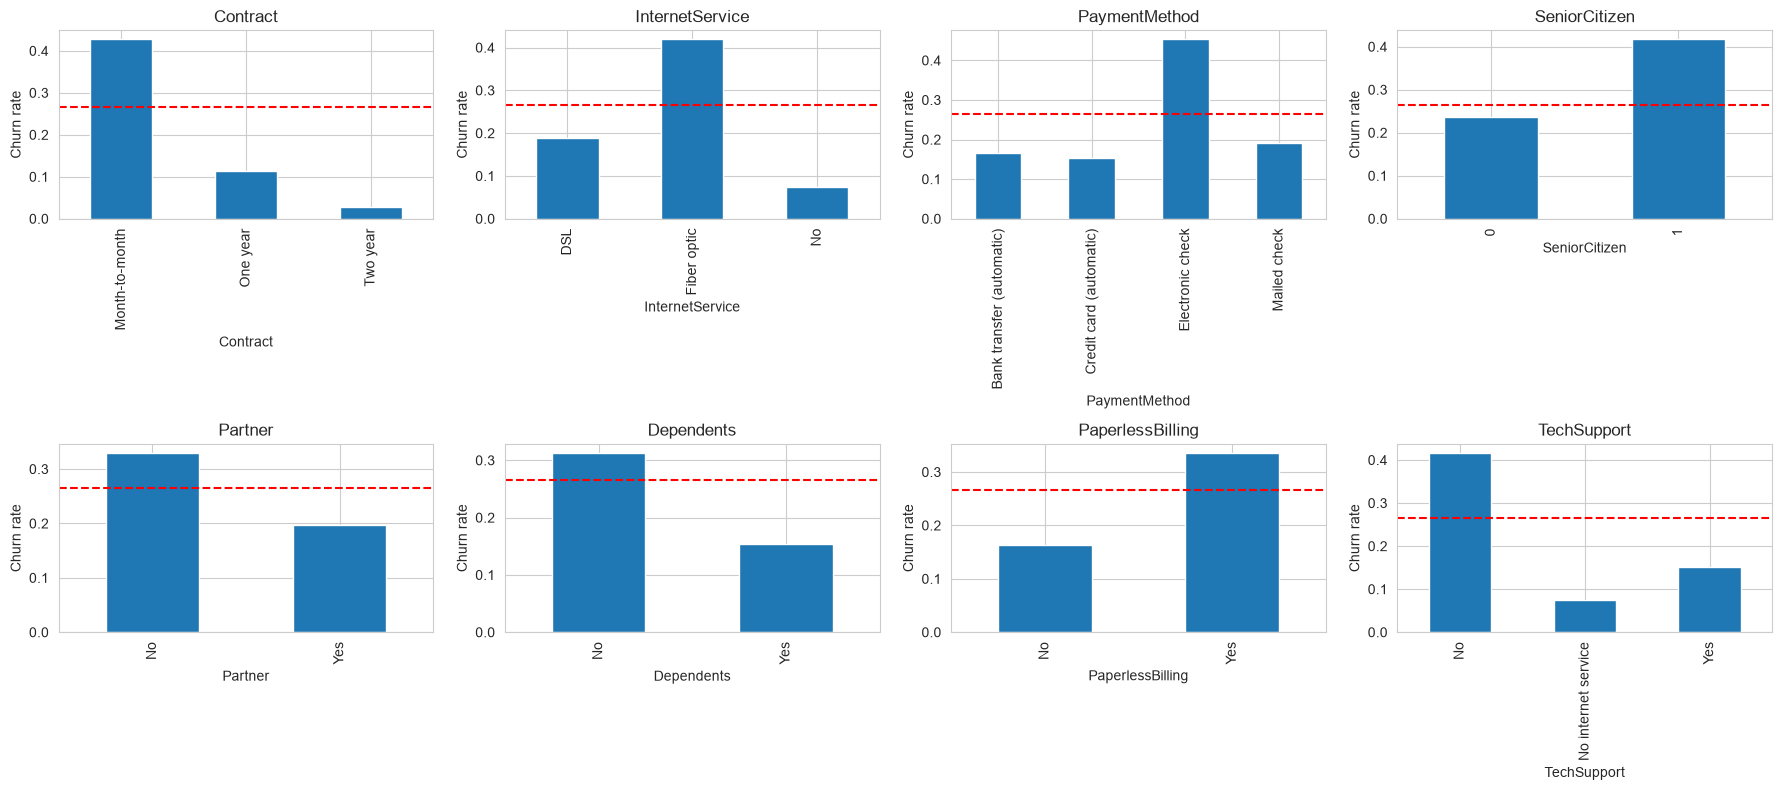

In [12]:
plt.close("all")
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, cols):
    rates = df_eda.groupby(col)["ChurnFlag"].mean()
    rates.plot(kind="bar", ax=ax, title=col)
    ax.axhline(df_eda["ChurnFlag"].mean(), color="red", linestyle="--")   # overall churn rate
    ax.set_ylabel("Churn rate")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/churn_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

**Chart:** Churn rate by contract type
**Shows:** month-to-month customers churn at 42.7%, one-year at 11.3% and two-year at 2.8%, against an overall rate of 26.5%.
**So what:** contract length looks like a very strong predictor. Month-to-month customers are the main retention target, and a a contract-upgrade offer could be tested as a possible action. Keep `Contract` as a key feature.

**Chart:** Churn rate by internet service
**Shows:** fiber optic customers churn at 41.9%, DSL at 19.0% and customers with no internet at 7.4%.
**So what:** fiber customers are high risk, but this is an association, not a proven cause. Fiber customers also pay much more (see section 9), so this chart alone cannot isolate the contribution of price versus technology.

**Chart:** Churn rate by payment method
**Shows:** electronic check payers churn at 45.3%, mailed check 19.1%, bank transfer (automatic) 16.7% and credit card (automatic) 15.2%.
**So what:** payment method is informative. The automatic methods may reflect more committed customers. Encode it as a categorical feature.

**Chart:** Churn rate by senior citizen status
**Shows:** senior citizens churn at 41.7% versus 23.6% for non-seniors.
**So what:** seniors are a higher-risk group. Because this is a demographic attribute, the responsible AI section should check that the model treats this group fairly.

In [13]:
rows = []
for col in ["gender", "Partner", "Dependents", "PaperlessBilling", "TechSupport"]:
    stats = df_eda.groupby(col)["ChurnFlag"].agg(["mean", "count"])
    for level, r in stats.iterrows():
        rows.append((col, level, round(r["mean"], 3), int(r["count"])))

summary = pd.DataFrame(rows, columns=["feature", "group", "churn_rate", "customers"])
summary.sort_values("churn_rate", ascending=False)

,feature,group,churn_rate,customers
8,TechSupport,No,0.416,3473
7,PaperlessBilling,Yes,0.336,4171
2,Partner,No,0.330,3641
4,Dependents,No,0.313,4933
0,gender,Female,0.269,3488
1,gender,Male,0.262,3555
3,Partner,Yes,0.197,3402
6,PaperlessBilling,No,0.163,2872
5,Dependents,Yes,0.155,2110
10,TechSupport,Yes,0.152,2044


**Chart:** Churn rate by tech support
**Shows:** customers without tech support churn at 41.6% (3,473 customers) versus 15.2% with it (2,044 customers). Customers with no internet service churn at 7.4% (1,526 customers).
**So what:** tech support shows a substantial churn-rate gap, and it is something the business can change, for example by bundling it into plans. Keep it as a feature.

**Chart:** Churn rate by partner and dependents
**Shows:** customers with no partner churn at 33.0% versus 19.7% with one. No dependents is 31.3% versus 15.5% with dependents.
**So what:** customers with household ties churn less, possibly because they are more settled. The two columns are related but not identical (see section 9), so M2 can evaluate whether both improve predictions.

**Chart:** Churn rate by paperless billing
**Shows:** paperless billing customers churn at 33.6% (4,171 customers) versus 16.3% for paper billing (2,872 customers).
**So what:** this is an association only. Paperless customers may differ in other ways (for example they may differ in payment method or contract type), which is why the later models are needed to separate the effects.

**Chart:** Churn rate by gender
**Shows:** female 26.9% and male 26.2%, essentially equal to the overall 26.5%.
**So what:** gender carries almost no signal for churn. It is a candidate to leave out, or at least to monitor for fairness in the responsible AI section.

In [14]:
rest = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
        "DeviceProtection", "StreamingTV", "StreamingMovies"]
rows = []
for col in rest:
    stats = df_eda.groupby(col)["ChurnFlag"].agg(["mean", "count"])
    for level, r in stats.iterrows():
        rows.append((col, level, round(r["mean"], 3), int(r["count"])))

service_summary = pd.DataFrame(
    rows, columns=["feature", "group", "churn_rate", "customers"]
).sort_values("churn_rate", ascending=False)
display(service_summary)

# Reproducible highlights; no invented percentages
substantive_groups = service_summary[service_summary["customers"] >= 100]
print("Overall churn rate:", f'{df_eda["ChurnFlag"].mean():.1%}')
print("Highest churn rate among groups of at least 100 customers:")
display(substantive_groups.head(3))
print("Lowest churn rate among groups of at least 100 customers:")
display(substantive_groups.tail(3))

,feature,group,churn_rate,customers
5,OnlineSecurity,No,0.418,3498
8,OnlineBackup,No,0.399,3088
11,DeviceProtection,No,0.391,3095
17,StreamingMovies,No,0.337,2785
14,StreamingTV,No,0.335,2810
16,StreamingTV,Yes,0.301,2707
19,StreamingMovies,Yes,0.299,2732
4,MultipleLines,Yes,0.286,2971
1,PhoneService,Yes,0.267,6361
2,MultipleLines,No,0.250,3390


Overall churn rate: 26.5%
Highest churn rate among groups of at least 100 customers:


,feature,group,churn_rate,customers
5,OnlineSecurity,No,0.418,3498
8,OnlineBackup,No,0.399,3088
11,DeviceProtection,No,0.391,3095


Lowest churn rate among groups of at least 100 customers:


,feature,group,churn_rate,customers
12,DeviceProtection,No internet service,0.074,1526
15,StreamingTV,No internet service,0.074,1526
18,StreamingMovies,No internet service,0.074,1526


**Table:** Churn rates for the remaining phone, security, backup, protection and streaming service categories.  
**Shows:** The cell above prints each group's *observed* churn rate and size, then highlights the highest and lowest rates among groups with at least 100 customers. Compare each value to the overall 26.5% churn rate. Groups labeled "No internet service" should also be interpreted alongside `InternetService` rather than as separate evidence of a service's effect.  
**So what:** Service-related variables may help characterize churn risk, but these descriptive comparisons do not establish that subscribing to a service causes customers to stay or leave. Member 2 should evaluate their predictive value after preprocessing and avoid treating overlapping service categories as independent evidence. The precise top/bottom groups must be read from the executed table, not guessed in the written report.

## 7. Tenure and charges

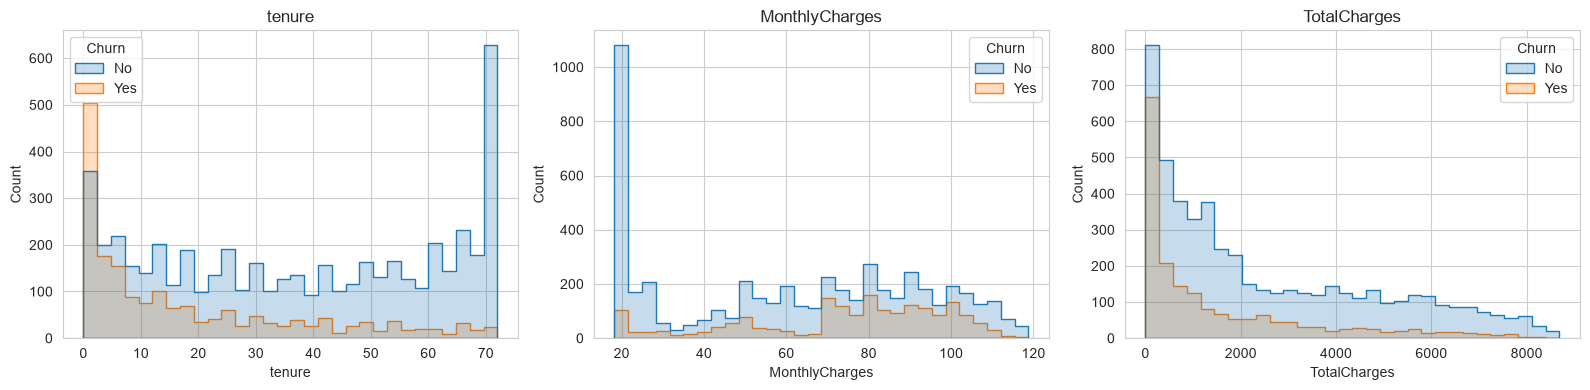

In [15]:
plt.close("all")
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.histplot(data=df_eda, x=col, hue="Churn", bins=30, ax=ax, element="step")
    ax.set_title(col)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/numeric_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
df_eda["tenure_band"] = pd.cut(df_eda["tenure"], bins=[-1, 12, 24, 48, 72],
                               labels=["0-12", "13-24", "25-48", "49-72"])

band = df_eda.groupby("tenure_band", observed=True)["ChurnFlag"].agg(
    churn_rate="mean", customers="count", churners="sum")
band["churn_rate"] = band["churn_rate"].round(3)
band["share_of_all_churners"] = (band["churners"] / band["churners"].sum()).round(3)
band
print("First-year churners:", int(band.loc["0-12", "churners"]))
print("Share of all churners in first 12 months:",
      f'{band.loc["0-12", "churners"] / band["churners"].sum():.2%}')

First-year churners: 1037
Share of all churners in first 12 months: 55.48%


**Chart:** Churn rate by tenure band
**Shows:** churn falls steadily with tenure: 47.4% (0-12 months, 2,186 customers), 28.7% (13-24, 1,024), 20.4% (25-48, 1,594) and 9.5% (49-72, 2,239).
**So what:** tenure is a very strong predictor, and the first year is the highest-risk period, so retention efforts should focus on new customers. A tenure band is a useful engineered feature, but M2 should keep the raw `tenure` column too, because banding throws away detail. The code cell calculates and prints the exact first-year share of all churners from the dataset; use that printed percentage when describing this result in the report.

**Chart:** Distributions of tenure, MonthlyCharges and TotalCharges by churn
**Shows:** churners concentrate at low tenure, in the mid-to-high monthly charge range (roughly $70 to $100) and at low total charges. There is a large group of non-churners near 72 months of tenure and another near $20 a month.
**So what:** monthly charges carry signal on their own. `TotalCharges` is closely related to tenure and monthly price, but whether it adds extra predictive value needs to be checked during modeling (see the correlation below). The group near $20 a month is consistent with the much lower average charge for customers without internet service (see section 9).

## 8. Outliers and correlation

In [17]:
df_eda[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


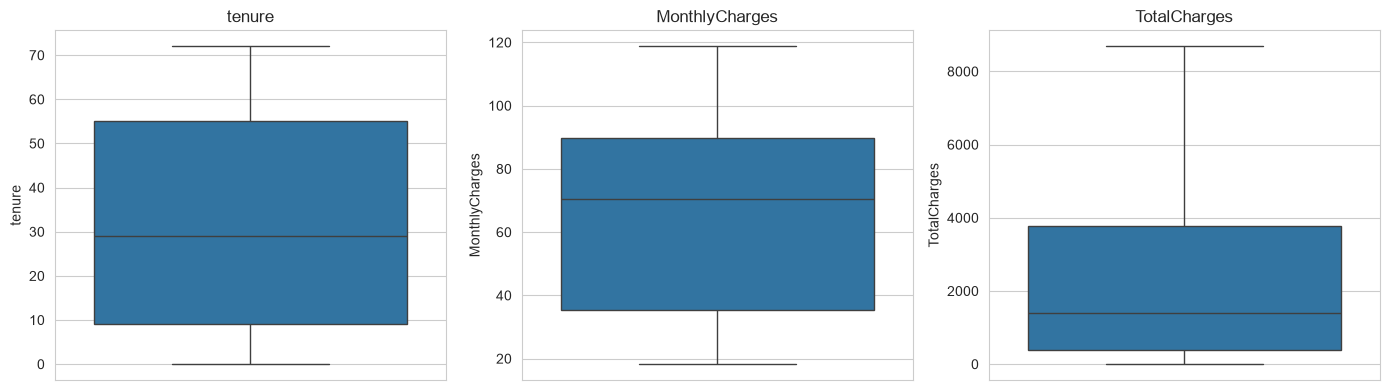

In [18]:
plt.close("all")
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.boxplot(data=df_eda, y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

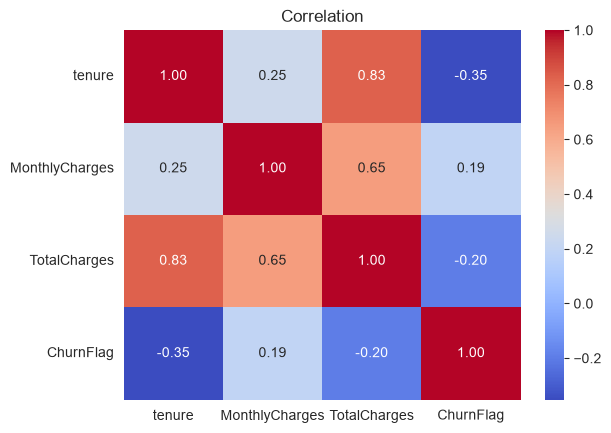

In [19]:
plt.close("all")
num = df_eda[["tenure", "MonthlyCharges", "TotalCharges", "ChurnFlag"]]
sns.heatmap(num.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation")
plt.savefig(f"{FIG_DIR}/correlation.png", dpi=150, bbox_inches="tight")
plt.show()

**Chart:** Boxplots of tenure, MonthlyCharges and TotalCharges
**Shows:** no points fall outside the whiskers in any of the three columns (exact minimum and maximum are in the summary table above). `TotalCharges` is right-skewed.
**So what:** the boxplot/IQR method does not flag outliers in these three columns; this check does not by itself rule out all data-quality concerns. Scaling is still recommended for distance-based and linear models because the three columns sit on very different scales.

**Chart:** Correlation heatmap (tenure, MonthlyCharges, TotalCharges, Churn)
**Shows:** `TotalCharges` correlates 0.83 with tenure and 0.65 with `MonthlyCharges`. Tenure has the strongest correlation with churn (-0.35), followed by `TotalCharges` (-0.20) and `MonthlyCharges` (0.19).
**So what:** `TotalCharges` is largely tenure multiplied by monthly price, which suggests possible redundancy and multicollinearity to assess in Logistic Regression. Suggest M2 test models with and without it. Tenure has the strongest *absolute linear correlation* with churn among these three numerical variables. The tenure-band table also suggests a relationship that need not be purely linear.

## 9. Follow-up checks

In [20]:
print("No internet customers:", (df_eda["InternetService"] == "No").sum())
print()
print(df_eda.groupby("InternetService")["MonthlyCharges"].mean().round(2))
print()
print(pd.crosstab(df_eda["Partner"], df_eda["Dependents"], normalize="index").round(2))

No internet customers: 1526

InternetService
DSL            58.10
Fiber optic    91.50
No             21.08
Name: MonthlyCharges, dtype: float64

Dependents    No   Yes
Partner               
No          0.90  0.10
Yes         0.49  0.51


**Chart:** Internet service vs monthly charges (updated)
**Shows:** 1,526 customers have no internet service, the same number as "No internet service" in the service columns. Average monthly charge is $58.10 for DSL, $91.50 for fiber optic and $21.08 for no internet.
**So what:** the "No internet service" value is redundant with `InternetService` and could be merged into "No" during preprocessing, if justified by Member 2. The low-charge spike near $20 is consistent with customers who do not use internet service; the chart alone does not identify every customer in that spike. Fiber customers pay about $33 a month more than DSL customers, so the high fiber churn may partly reflect price. This simple grouped comparison cannot separate price from technology, so the business should investigate fiber pricing and service quality before acting.

**Chart:** Partner vs Dependents crosstab
**Shows:** 51% of customers with a partner have dependents versus 10% of those without a partner. About 90% of customers with no partner have no dependents.
**So what:** the two columns overlap partially but are not duplicates, so both can stay in the first modeling round. M2 can check whether either adds value, and models that handle correlated inputs will cope either way.

## 10. Summary for the team

**Key findings (associations, not proven causes):**
- Churn is 26.5% overall, so the classes are imbalanced.
- Highest-risk groups: month-to-month contracts, tenure under 12 months, fiber optic internet, electronic check payment, no tech support, senior citizens, and customers with no partner or dependents.
- Gender carries almost no signal.
- `TotalCharges` is strongly correlated with tenure (0.83); its extra predictive value should be tested rather than assumed.

**Handoff to M2:** the data issues list in section 4. Final preprocessing decisions belong to M2 and go in the decision log.

**Limitations:** this is a single snapshot in time. Long-tenure customers are partly the ones who stayed, so some of the tenure pattern is survivorship. Bar charts show one factor at a time, and factors overlap, so only the models can separate their effects.